# Stems segmentation

In [ ]:
import os
import json
import yaml
import numpy as np
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob

## Setup

Folders organization:

In [ ]:
BASE_DIR = "."  

MEDLEYDB_ROOT = os.path.join(BASE_DIR, "MedleyDB")
AUDIO_DIR = os.path.join(MEDLEYDB_ROOT, "Audio")
ANNOTATIONS_DIR = os.path.join(MEDLEYDB_ROOT, "Annotations")

INSTRUMENT_ACTIVATIONS_DIR = os.path.join(ANNOTATIONS_DIR, "Instrument_Activations")
ACTIVATION_CONF_DIR = os.path.join(INSTRUMENT_ACTIVATIONS_DIR, "ACTIVATION_CONF")
SOURCEID_DIR = os.path.join(INSTRUMENT_ACTIVATIONS_DIR, "SOURCEID")

Define the instrument mapping from all the dataset categories into 18 custom classes:

In [ ]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

Utility functions:

In [12]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.

    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """

    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)

    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break

    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]

    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(10, max(8, len(names) * 0.3)))

    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')

    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')

    # Adjust margins
    plt.tight_layout()

    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')

    # Show the plot
    plt.show()

def sanitize_directory_name(name):
    """
    Converts an instrument name into a safe directory name.

    Args:
        name: Original instrument name

    Returns:
        str: Sanitized name safe to use as a directory name
    """

    # Replace problematic characters with descriptive strings
    replacements = {
        '/': '_slash_',
        '\\': '_backslash_',
        ':': '_colon_',
        '*': '_star_',
        '?': '_question_',
        '"': '_quote_',
        '<': '_lt_',
        '>': '_gt_',
        '|': '_pipe_',
        ' ': '_'  # Also replace spaces with underscores
    }

    result = name
    for char, replacement in replacements.items():
        result = result.replace(char, replacement)

    return result

def desanitize_directory_name(sanitized_name):
    """
    Converts a sanitized directory name back to the original name.

    Args:
        sanitized_name: Sanitized directory name

    Returns:
        str: Original instrument name
    """

    # Replace in reverse order
    replacements = {
        '_slash_': '/',
        '_backslash_': '\\',
        '_colon_': ':',
        '_star_': '*',
        '_question_': '?',
        '_quote_': '"',
        '_lt_': '<',
        '_gt_': '>',
        '_pipe_': '|',
        '_': ' '  # Important: this should go last
    }

    result = sanitized_name
    for replacement, char in replacements.items():
        result = result.replace(replacement, char)

    return result

def count_extracted_segments(base_directory="extracted_segments"):
    """
    Counts the number of WAV files in each instrument folder.

    Args:
        base_directory: Base directory where the instrument folders are located

    Returns:
        OrderedDict: Ordered dictionary with counts per instrument (from most to least)
    """

    if not os.path.exists(base_directory):
        print(f"Error: Directory {base_directory} does not exist")
        return {}

    # Get all folders (each represents an instrument)
    instrument_dirs = [d for d in os.listdir(base_directory)
                      if os.path.isdir(os.path.join(base_directory, d))]

    # Count files per instrument
    counts = {}
    total_files = 0

    for dir_name in instrument_dirs:
        instrument = desanitize_directory_name(dir_name)
        # Convert the directory name back to the instrument name
        instrument = dir_name.replace("_", " ")

        # Count WAV files in this folder
        instrument_path = os.path.join(base_directory, dir_name)
        files = [f for f in os.listdir(instrument_path)
                if f.endswith(".wav") and os.path.isfile(os.path.join(instrument_path, f))]

        num_files = len(files)
        counts[instrument] = num_files
        total_files += num_files

    # Sort by number of files (descending)
    sorted_counts = OrderedDict(sorted(counts.items(), key=lambda x: x[1], reverse=True))

    # Show summary
    print(f"Total extracted segments: {total_files}")
    print("\nSegments per instrument:")
    for instrument, count in sorted_counts.items():
        print(f"- {instrument}: {count} segments")

    return sorted_counts

def get_class_idx(original_instrument_name):
    # Apply desanitize to the instrument name
    instrument_name = desanitize_directory_name(original_instrument_name)

    if instrument_name in instruments_to_discard:
        return None

    # Replace spaces with underscores if necessary
    normalized_name = instrument_name.replace(" ", "_")

    if normalized_name in instrument_mapping:
        category = instrument_mapping[normalized_name]
        return category_to_idx[category]
    else:
        # If not in the mapping, check if the original name is
        if original_instrument_name in instrument_mapping:
            category = instrument_mapping[original_instrument_name]
            return category_to_idx[category]
        return None

def get_metadata_file_path(track_name):
    """Gets the path to the YAML metadata file for a track"""
    return os.path.join(MEDLEYDB_ROOT, "Audio", track_name, f"{track_name}_METADATA.yaml")

def extract_track_instruments(track_names):
    """
    Extracts the instruments for each track in the order of their STEMs.

    Args:
        track_names: List of track names

    Returns:
        list: List of lists, where each sublist contains the instruments 
              in STEM order for a track
    """

    all_instruments = []

    for track_name in track_names:
        metadata_path = get_metadata_file_path(track_name)

        if not os.path.exists(metadata_path):
            print(f"Warning: Metadata not found for {track_name}")
            # Add empty list to keep alignment with track_names
            all_instruments.append([])
            continue

        try:
            with open(metadata_path, 'r') as f:
                metadata = yaml.safe_load(f)

            # Extract instruments in STEM order
            instruments = []

            if 'stems' in metadata:
                # Sort STEMs by number (S01, S02, etc.)
                stem_ids = sorted(metadata['stems'].keys())

                for stem_id in stem_ids:
                    stem_data = metadata['stems'][stem_id]
                    if 'instrument' in stem_data:
                        instrument = stem_data['instrument']
                        instruments.append(instrument)

            all_instruments.append(instruments)
            print(f"Processed: {track_name} - {len(instruments)} instruments")

        except Exception as e:
            print(f"Error processing {track_name}: {e}")
            all_instruments.append([])  # Empty list in case of error

    return all_instruments

def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.

    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """

    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)

    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break

    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]

    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(10, max(8, len(names) * 0.3)))

    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')

    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')

    # Adjust margins
    plt.tight_layout()

    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')

    # Show the plot
    plt.show()

def get_activation_intervals(track_name, instrument):
    """
    Gets the activation intervals for a specific instrument.

    Args:
        track_name: Track name
        instrument: Instrument name

    Returns:
        list: List of tuples (start_time, end_time)
    """

    sourceid_path = os.path.join(SOURCEID_DIR, f"{track_name}_SOURCEID.lab")

    intervals = []
    if os.path.exists(sourceid_path):
        with open(sourceid_path, 'r') as f:
            header = f.readline()  # Skip header
            for line in f:
                parts = line.strip().split(',')
                if len(parts) >= 3 and parts[2].strip() == instrument:
                    start_time = float(parts[0])
                    end_time = float(parts[1])
                    intervals.append((start_time, end_time))

    return intervals

def get_stem_path(track_name, instrument):
    """
    Gets the path to the STEM file for a specific instrument.

    Args:
        track_name: Track name
        instrument: Instrument name

    Returns:
        str: Path to the STEM file
    """

    # 1. Get the metadata to find which STEM corresponds to this instrument
    metadata_path = get_metadata_file_path(track_name)

    with open(metadata_path, 'r') as f:
        metadata = yaml.safe_load(f)

    # 2. Find the STEM ID that corresponds to this instrument
    stem_id = None
    for stem, data in metadata['stems'].items():
        if data.get('instrument') == instrument:
            stem_id = stem
            break

    if stem_id is None:
        return None

    # 3. Build the path to the STEM file
    stem_number = stem_id[1:] if stem_id.startswith('S') else stem_id
    return os.path.join(AUDIO_DIR, track_name, f"{track_name}_STEMS", 
                       f"{track_name}_STEM_{stem_number}.wav")

def extract_audio_segments(track_name, instrument, segment_duration=3.0, overlap=0.5):
    """
    Extracts fixed-duration audio segments for a specific instrument.

    Args:
        track_name: Track name
        instrument: Instrument name
        segment_duration: Duration of each segment in seconds
        overlap: Overlap between consecutive segments

    Returns:
        list: List of NumPy arrays with the audio segments
    """

    # 1. Get activation intervals
    intervals = get_activation_intervals(track_name, instrument)

    # 2. Get the path to the STEM file
    stem_path = get_stem_path(track_name, instrument)

    if stem_path is None or not os.path.exists(stem_path):
        print(f"STEM file not found for {instrument} in {track_name}")
        return []

    # 3. Extract audio segments
    segments = []
    for start_time, end_time in intervals:
        duration = end_time - start_time

        # Skip intervals that are too short
        if duration < segment_duration:
            continue

        # Load the audio
        try:
            y, sr = librosa.load(stem_path, sr=44100, offset=start_time, duration=duration)

            # Extract segments with overlap
            step = segment_duration * (1 - overlap)
            t = 0.0

            while t + segment_duration <= duration:
                segment_start = int(t * sr)
                segment_end = int((t + segment_duration) * sr)

                if segment_end <= len(y):
                    segment = y[segment_start:segment_end]
                    segments.append(segment)

                t += step

        except Exception as e:
            print(f"Error processing audio {stem_path}: {e}")

    return segments

def extract_and_save_segments(instrument_counts, track_names, all_instruments, 
                             segment_duration=3.0, overlap=0.5,
                             top_n=None):
    """
    Extracts and saves audio segments for selected instruments.
    """

    # Fixed directory to save
    extracted_directory = "extracted_segments"
    os.makedirs(extracted_directory, exist_ok=True)

    # Select instruments (top N most frequent)
    sorted_instruments = sorted(instrument_counts.items(), 
                              key=lambda x: x[1], reverse=True)

    if top_n is not None:
        selected_instruments = [item[0] for item in sorted_instruments[:top_n]]
    else:
        selected_instruments = [item[0] for item in sorted_instruments]

    print(f"Processing {len(selected_instruments)} selected instruments")

    # Process each selected instrument
    for instrument in tqdm(selected_instruments, desc="Instruments"):
        # Sanitize the instrument name for the directory
        instrument_dir_name = sanitize_directory_name(instrument)
        instrument_directory = os.path.join(extracted_directory, instrument_dir_name)
        os.makedirs(instrument_directory, exist_ok=True)

        # Counter for total segments of this instrument
        total_segments = 0

        # Process each song
        for i, track_name in enumerate(tqdm(track_names, desc=f"Tracks for {instrument}", leave=False)):
            # Check if this instrument is in this song
            if instrument in all_instruments[i]:
                try:
                    # CORRECTION: Only one value returned
                    segments = extract_audio_segments(track_name, instrument, 
                                                    segment_duration, overlap)

                    # Fixed sample rate for saving
                    sr = 44100

                    # Save each segment
                    for j, segment in enumerate(segments):
                        # File name: artist_song_nnn.wav
                        filename = f"{track_name}_{j:03d}.wav"
                        filepath = os.path.join(instrument_directory, filename)

                        # Save as WAV file
                        sf.write(filepath, segment, sr)
                        total_segments += 1

                except Exception as e:
                    print(f"\nError processing {track_name}, {instrument}: {e}")

        print(f"\n- {instrument}: {total_segments} segments saved")

def process_and_save_features(base_dir="extracted_segments", feature_types=["cqt", "mel"]):
    """
    Processes the WAV files and saves the feature matrices with 
    dimensions (96, 128) - 96 frequency bins and 128 time frames.

    Args:
        base_dir: Base directory containing the instrument folders
        feature_types: List of feature types to compute ("cqt", "mel")
    """
    
    # Parameters for the features
    sr = 44100  # Sample rate
    n_fft = 2048  # FFT size
    hop_length = 1024  # To get about 130 frames in 3 seconds

    # Specific configuration for CQT
    cqt_params = {
        'n_bins': 96,             # 96 bins as in the paper
        'bins_per_octave': 12,    # 12 semitones per octave (8 octaves)
        'hop_length': hop_length,
        'fmin': librosa.note_to_hz('C1')  # Start from C1
    }

    # Specific configuration for Mel-spectrogram
    mel_params = {
        'n_mels': 96,             # 96 bins as in the paper
        'n_fft': n_fft,
        'hop_length': hop_length
    }

    # Get all instrument folders
    instrument_dirs = [d for d in os.listdir(base_dir) 
                      if os.path.isdir(os.path.join(base_dir, d))]

    # Process each instrument folder
    for instrument_dir in tqdm(instrument_dirs, desc="Processing instruments"):
        instrument_path = os.path.join(base_dir, instrument_dir)

        # Get all WAV files
        wav_files = [f for f in os.listdir(instrument_path) 
                    if f.endswith(".wav") and os.path.isfile(os.path.join(instrument_path, f))]

        # Process each WAV file
        for wav_file in tqdm(wav_files, desc=f"Files in {instrument_dir}"):#leave=False
            wav_path = os.path.join(instrument_path, wav_file)

            # Create base name without extension
            base_name = os.path.splitext(wav_file)[0]

            # Create folder to save features
            features_dir = os.path.join(instrument_path, base_name)
            os.makedirs(features_dir, exist_ok=True)

            # Load the audio
            try:
                audio, sr_file = sf.read(wav_path)

                # Convert to mono if stereo
                if len(audio.shape) > 1 and audio.shape[1] > 1:
                    audio = np.mean(audio, axis=1)

                # Resample if necessary
                if sr_file != sr:
                    audio = librosa.resample(audio, orig_sr=sr_file, target_sr=sr)

                # Compute and save each type of feature
                for feature_type in feature_types:
                    if feature_type == "cqt":
                        # Compute CQT
                        C = librosa.cqt(audio, sr=sr, **cqt_params)
                        log_C = librosa.amplitude_to_db(np.abs(C))

                        # Save CQT matrix
                        feature_name = f"cqt_{cqt_params['n_bins']}bins_hop{hop_length}.npy"
                        np.save(os.path.join(features_dir, feature_name), log_C)

                    elif feature_type == "mel":
                        # Compute mel-spectrogram
                        S = librosa.feature.melspectrogram(y=audio, sr=sr, **mel_params)
                        log_S = librosa.power_to_db(S)

                        # Save Mel matrix
                        feature_name = f"mel_{mel_params['n_mels']}bins_hop{hop_length}.npy"
                        np.save(os.path.join(features_dir, feature_name), log_S)

            except Exception as e:
                print(f"\nError processing {wav_path}: {e}")


Counting number of segments per class:

Total extracted segments: 69653

Segments per instrument:
- electric bass: 6781 segments
- drum set: 6300 segments
- piano: 5039 segments
- clean electric guitar: 4790 segments
- synthesizer: 4594 segments
- tabla: 3707 segments
- fx slash processed sound: 3415 segments
- violin: 3010 segments
- drum machine: 2917 segments
- male singer: 2776 segments
- distorted electric guitar: 2475 segments
- acoustic guitar: 2452 segments
- female singer: 2190 segments
- vocalists: 1565 segments
- mandolin: 1502 segments
- auxiliary percussion: 1442 segments
- double bass: 1440 segments
- accordion: 1260 segments
- cello: 1106 segments
- viola: 875 segments
- flute: 622 segments
- tack piano: 565 segments
- string section: 504 segments
- clarinet: 444 segments
- vibraphone: 440 segments
- violin section: 440 segments
- harp: 424 segments
- brass section: 384 segments
- male rapper: 384 segments
- cymbal: 349 segments
- horn section: 319 segments
- bassoon: 298 segments
- cello section: 240 segments

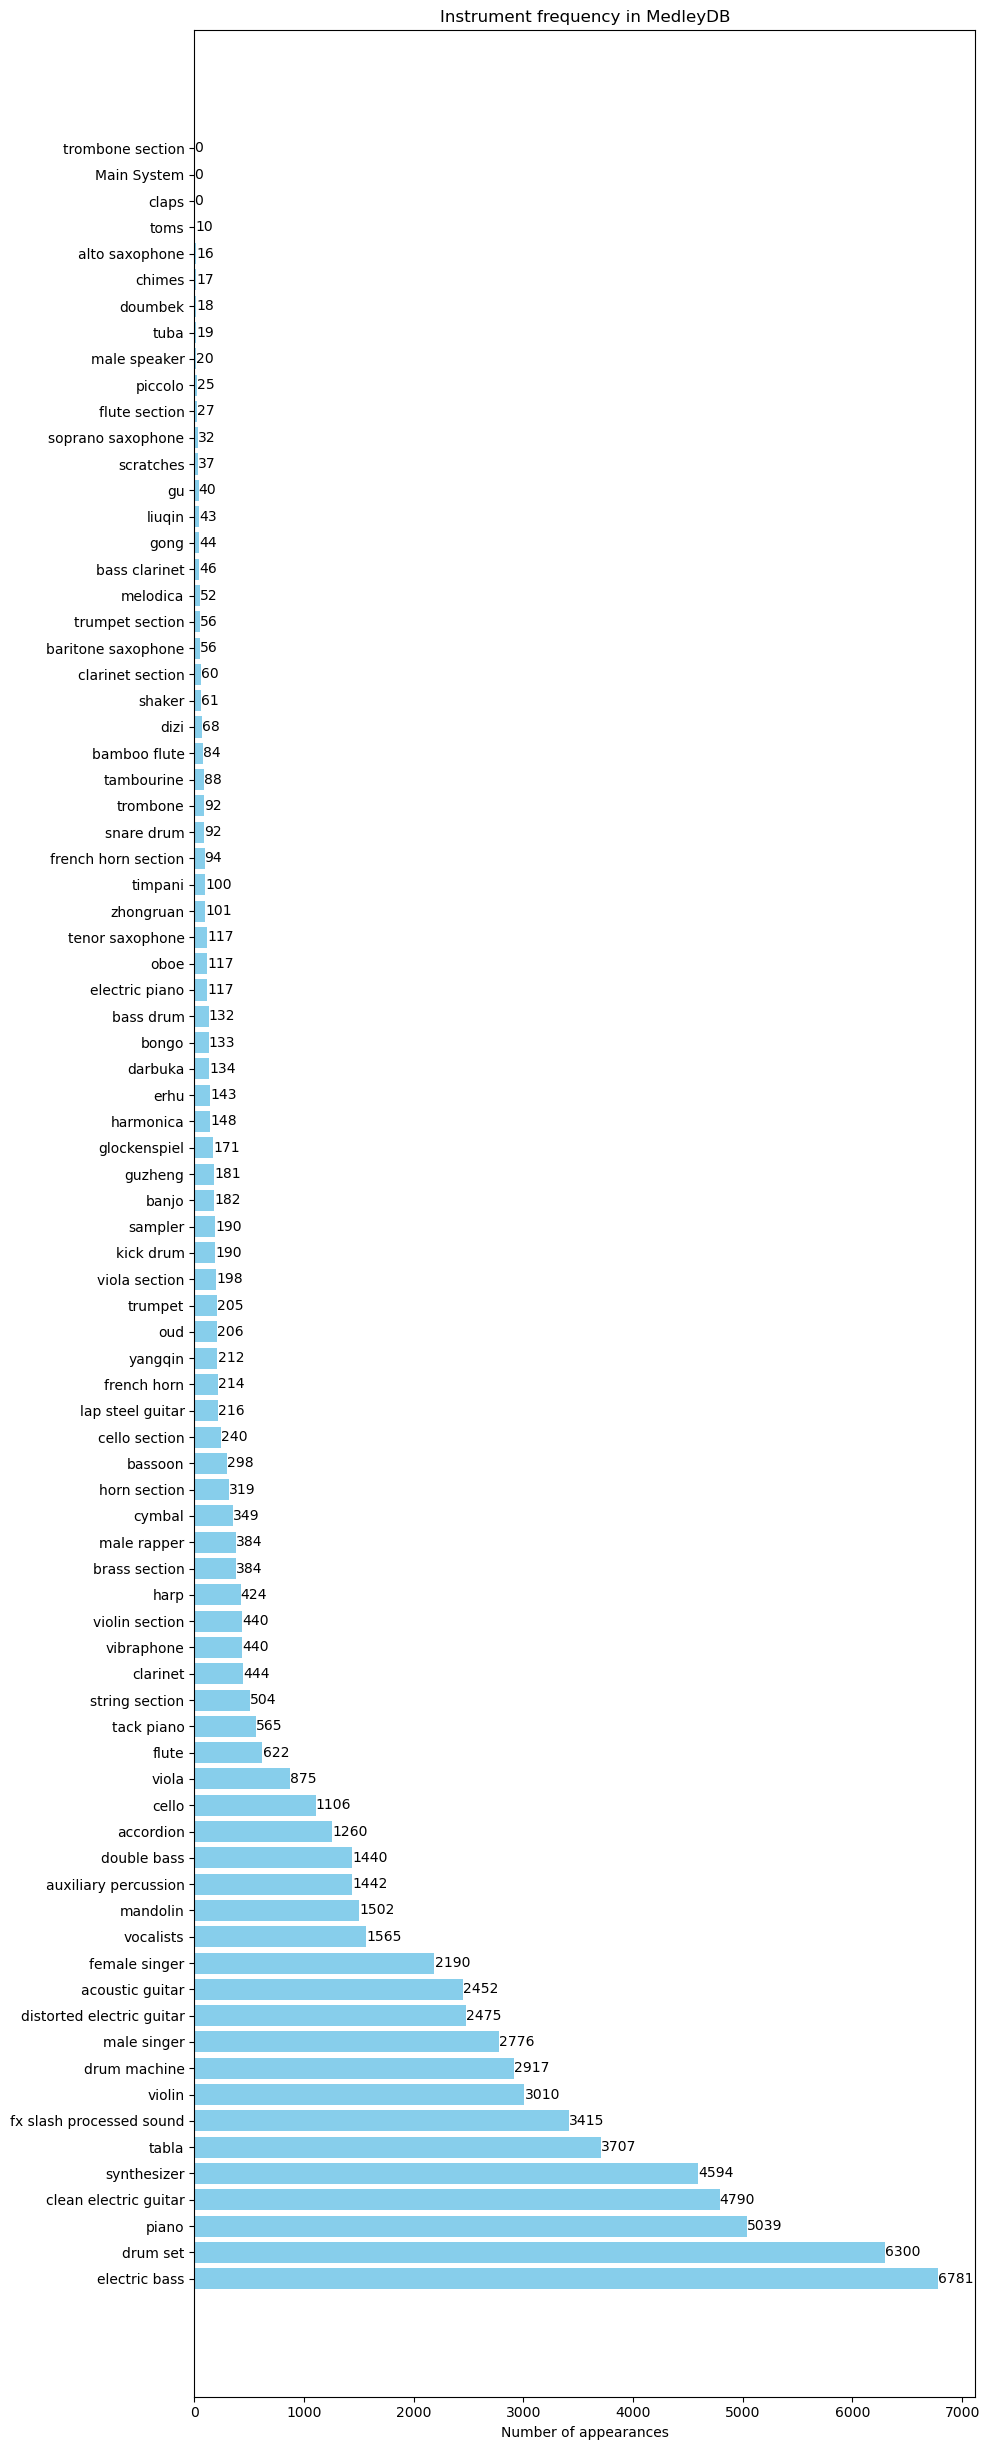

In [5]:
segments_per_instrument = count_extracted_segments()
plot_instrument_histogram(segments_per_instrument,top_n =82)

## Feature extraction

Extracting cqt or mel features:

In [6]:
# Configuration
base_path = os.path.normpath("extracted_segments")  # Normalize the path
feature_type = "cqt"  # or "mel"
test_size = 0.2
random_state = 42

# Determine the feature file
if feature_type == "cqt":
    feature_filename = "cqt_96bins_hop1024.npy"
elif feature_type == "mel":
    feature_filename = "mel_96bins_hop1024.npy"
else:
    raise ValueError(f"Unsupported feature type: {feature_type}")

# Get the list of instruments (folders)
instrument_dirs = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]

# Lists to store data
features = []
labels = []
instrument_counts = {category: 0 for category in instrument_categories}
instrument_counts["unknown"] = 0  # Add unknown category to handle unmapped cases
skipped_instruments = {}

print(f"Loading {feature_type} features with the defined classification scheme...")

# Iterate over each instrument folder
for instrument_dir in tqdm(instrument_dirs):
    # Use os.path.join to build paths safely on any platform
    instrument_path = os.path.join(base_path, instrument_dir)
    
    # Check if this instrument should be included
    class_idx = get_class_idx(instrument_dir)
    
    if class_idx is None:
        skipped_instruments[instrument_dir] = "discarded instrument"
        continue
    
    try:
        # Find all subfolders that contain features
        feature_folders = [d for d in os.listdir(instrument_path) 
                          if os.path.isdir(os.path.join(instrument_path, d))]
        
        # Load each feature file
        for folder in feature_folders:
            # Build the file path safely
            feature_file = os.path.join(instrument_path, folder, feature_filename)
            feature_file = os.path.normpath(feature_file)  # Normalize the path
            
            if os.path.exists(feature_file):
                # Load the .npy file
                feature_data = np.load(feature_file)
                
                # Add to our lists
                features.append(feature_data)
                labels.append(class_idx)
                
                # Increment counter for this category
                category = instrument_mapping.get(instrument_dir, "unknown")
                if category in instrument_counts:
                    instrument_counts[category] += 1
                else:
                    instrument_counts[category] = 1
            else:
                if instrument_dir not in skipped_instruments:
                    skipped_instruments[instrument_dir] = f"file not found: {feature_file}"
    except Exception as e:
        print(f"Error processing {instrument_path}: {type(e).__name__}: {e}")
        skipped_instruments[instrument_dir] = f"error: {str(e)}"
        continue

Loading cqt features with the defined classification scheme...


100%|██████████| 82/82 [05:39<00:00,  4.14s/it]


Saving the extracted features with according names:

In [7]:
# After processing all the data
X = np.array(features)
y = np.array(labels)

# Save only the arrays
np.save(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'), X)  # or cqt
np.save(os.path.join('extracted_segments_features', 'processed_labels_cqt.npy'), y)

print(f"Data saved: {X.shape} features and {y.shape} labels")

Data saved: (68879, 96, 130) features and (68879,) labels


Number of segments for our custom classes:

In [8]:
instrument_counts

{'electric_bass': 6781,
 'drum_set': 6300,
 'piano': 5604,
 'synthesizer': 4711,
 'clean_electric_guitar': 4790,
 'distorted_electric_guitar': 2475,
 'acoustic_guitar': 2452,
 'violin': 3010,
 'female_singer': 2190,
 'vocalists': 1565,
 'male_vocals': 3180,
 'other_bowed_strings': 4946,
 'woodwinds': 1860,
 'brass': 1383,
 'other_percussion': 9085,
 'other_plucked_strings': 3635,
 'reed_instruments': 1460,
 'fx_and_processed': 3452,
 'unknown': 0}

## Stems segmentation

In [10]:
if not os.path.exists(AUDIO_DIR):
    print(f"Error: Directory {AUDIO_DIR} does not exist.")

# Get only the directories (ignore files)
else:
    track_names = [item for item in os.listdir(AUDIO_DIR) if os.path.isdir(os.path.join(AUDIO_DIR, item))]
    print(f" {len(track_names)} songs where found.")

 122 songs where found.


Extracting instrument and stem from track:

In [13]:
all_instruments = extract_track_instruments(track_names)    # all_instruments[i][j]: i instrument, j stem

Processed: AClassicEducation_NightOwl - 13 instruments
Processed: AimeeNorwich_Child - 7 instruments
Processed: AimeeNorwich_Flying - 15 instruments
Processed: AlexanderRoss_GoodbyeBolero - 9 instruments
Processed: AlexanderRoss_VelvetCurtain - 10 instruments
Processed: AmarLal_Rest - 2 instruments
Processed: AmarLal_SpringDay1 - 1 instruments
Processed: Auctioneer_OurFutureFaces - 10 instruments
Processed: AvaLuna_Waterduct - 8 instruments
Processed: BigTroubles_Phantom - 7 instruments
Processed: BrandonWebster_DontHearAThing - 3 instruments
Processed: BrandonWebster_YesSirICanFly - 2 instruments
Processed: CelestialShore_DieForUs - 9 instruments
Processed: ChrisJacoby_BoothShotLincoln - 4 instruments
Processed: ChrisJacoby_PigsFoot - 4 instruments
Processed: ClaraBerryAndWooldog_AirTraffic - 8 instruments
Processed: ClaraBerryAndWooldog_Boys - 9 instruments
Processed: ClaraBerryAndWooldog_Stella - 8 instruments
Processed: ClaraBerryAndWooldog_TheBadGuys - 2 instruments
Processed: Cla

In [14]:
instrument_counts = {}

# Iterate over all instrument lists
for track_instruments in all_instruments:
    for instrument in track_instruments:
        if instrument in instrument_counts:
            instrument_counts[instrument] += 1
        else:
            instrument_counts[instrument] = 1

# Get count of unique instruments
unique_count = len(instrument_counts)

# Sort instruments by frequency (from most to least)
sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)

# Show results
print(f"\nTotal unique instruments in the dataset: {unique_count}")
print("\nInstruments sorted by frequency:")
for i, (instrument, count) in enumerate(sorted_instruments):
    print(f"{i+1}. {instrument}: {count} tracks")


Total unique instruments in the dataset: 82

Instruments sorted by frequency:
1. drum set: 66 tracks
2. electric bass: 63 tracks
3. clean electric guitar: 57 tracks
4. synthesizer: 47 tracks
5. male singer: 44 tracks
6. piano: 43 tracks
7. fx/processed sound: 41 tracks
8. distorted electric guitar: 33 tracks
9. vocalists: 33 tracks
10. female singer: 32 tracks
11. violin: 27 tracks
12. acoustic guitar: 26 tracks
13. auxiliary percussion: 18 tracks
14. drum machine: 18 tracks
15. violin section: 18 tracks
16. double bass: 17 tracks
17. tabla: 16 tracks
18. cello: 13 tracks
19. flute: 12 tracks
20. tack piano: 10 tracks
21. clarinet: 9 tracks
22. brass section: 9 tracks
23. mandolin: 9 tracks
24. vibraphone: 8 tracks
25. viola: 8 tracks
26. trumpet: 8 tracks
27. timpani: 7 tracks
28. cymbal: 7 tracks
29. string section: 6 tracks
30. male rapper: 6 tracks
31. french horn: 6 tracks
32. bassoon: 6 tracks
33. Main System: 6 tracks
34. erhu: 6 tracks
35. yangqin: 6 tracks
36. claps: 5 tracks

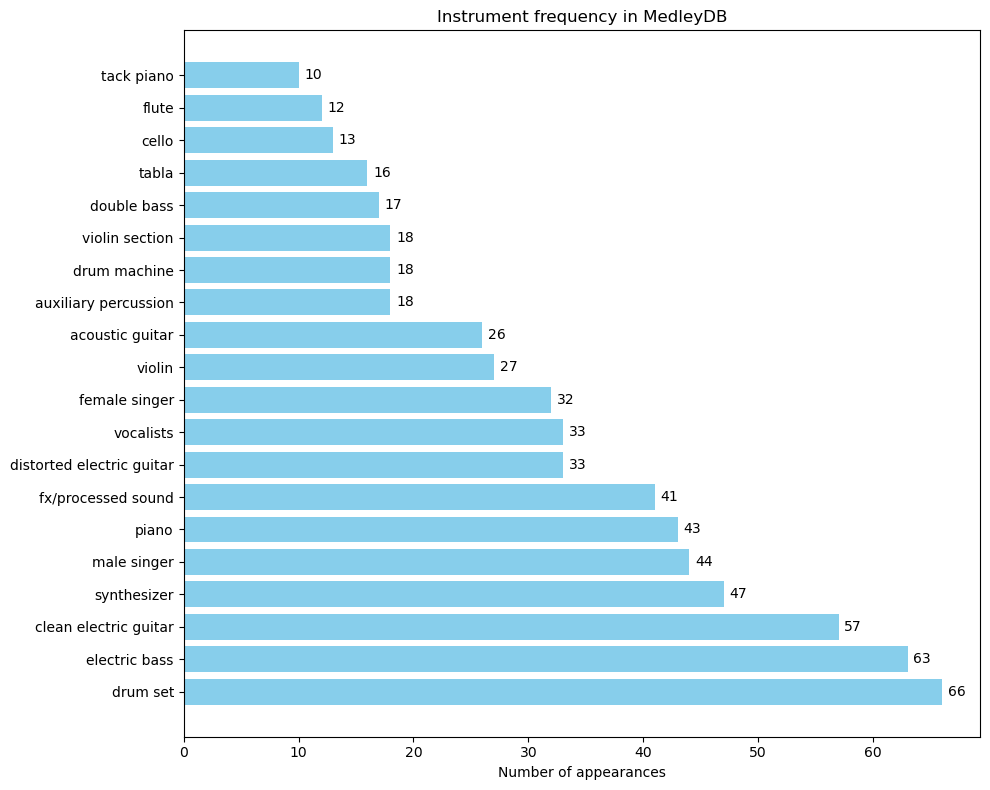

In [15]:
# Create histogram of the 20 most frequent instruments
plot_instrument_histogram(instrument_counts, top_n=20)

# Alternative: show only instruments with at least 5 appearances
# plot_instrument_histogram(instrument_counts, top_n=None, min_count=5)

In [16]:
extract_and_save_segments(
    instrument_counts=instrument_counts,
    track_names=track_names,
    all_instruments=all_instruments,
    segment_duration=3.0,
    overlap=0.5,
    top_n=83            # Limit to the 83 most frequent instruments
)

Processing 82 selected instruments


Instruments:   1%|          | 1/82 [00:46<1:03:23, 46.95s/it]


- drum set: 6300 segments saved


Instruments:   2%|▏         | 2/82 [01:31<1:00:57, 45.72s/it]


- electric bass: 6781 segments saved


...


- alto saxophone: 16 segments saved


Instruments:  99%|█████████▉| 81/82 [07:37<00:00,  4.09it/s]


- soprano saxophone: 32 segments saved


Instruments: 100%|██████████| 82/82 [07:37<00:00,  5.58s/it]


- toms: 10 segments saved


Total extracted segments: 69653

Segments per instrument:
- electric bass: 6781 segments
- drum set: 6300 segments
- piano: 5039 segments
- clean electric guitar: 4790 segments
- synthesizer: 4594 segments
- tabla: 3707 segments
- fx slash processed sound: 3415 segments
- violin: 3010 segments
- drum machine: 2917 segments
- male singer: 2776 segments
- distorted electric guitar: 2475 segments
- acoustic guitar: 2452 segments
- female singer: 2190 segments
- vocalists: 1565 segments
- mandolin: 1502 segments
- auxiliary percussion: 1442 segments
- double bass: 1440 segments
- accordion: 1260 segments
- cello: 1106 segments
- viola: 875 segments
- flute: 622 segments
- tack piano: 565 segments
- string section: 504 segments
- clarinet: 444 segments
- vibraphone: 440 segments
- violin section: 440 segments
- harp: 424 segments
- brass section: 384 segments
- male rapper: 384 segments
- cymbal: 349 segments
- horn section: 319 segments
- bassoon: 298 segments
- cello section: 240 segments

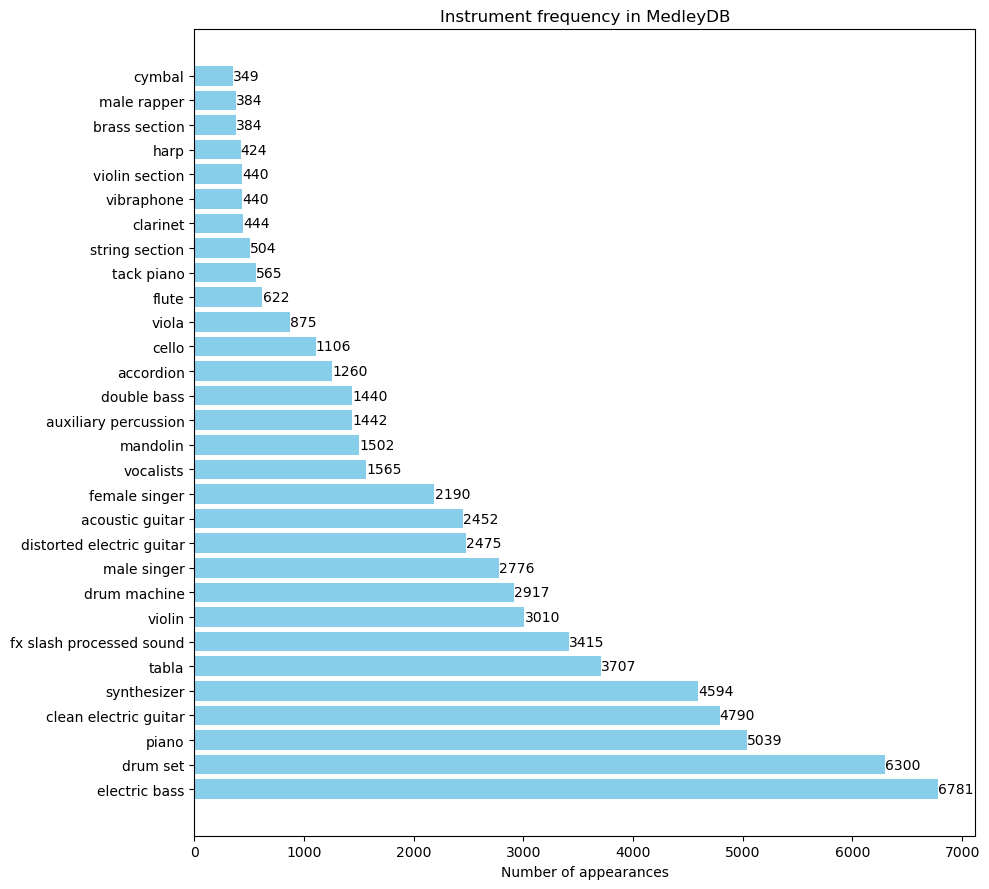

In [17]:
# Example of use
segments_per_instrument = count_extracted_segments()
plot_instrument_histogram(segments_per_instrument, top_n=30)

In [18]:
process_and_save_features(
    base_dir="extracted_segments", 
    feature_types=["cqt"]
)

Files in chimes: 100%|██████████| 17/17 [00:00<00:00, 30.09it/s]54s/it]
Files in claps: 0it [00:00, ?it/s]     | 15/82 [04:29<11:31, 10.33s/it]
Files in liuqin: 100%|██████████| 43/43 [00:01<00:00, 30.56it/s]36s/it]
Files in Main_System: 0it [00:00, ?it/s] 46/82 [23:49<04:11,  6.98s/it]
Files in trombone: 100%|██████████| 92/92 [00:02<00:00, 31.29it/s]s/it]
Files in trombone_section: 0it [00:00, ?it/s]2 [35:07<02:19, 11.65s/it]
Processing instruments: 100%|██████████| 82/82 [39:02<00:00, 28.57s/it]
